In [ ]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (2,807 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependen

In [ ]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Overwriting main.cpp


In [ ]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [ ]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Overwriting setup.sh


In [ ]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [8]:
!nvidia-smi
!nvcc --version

Sun Nov  1 20:03:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Kenar noktasi sayisi: 29573


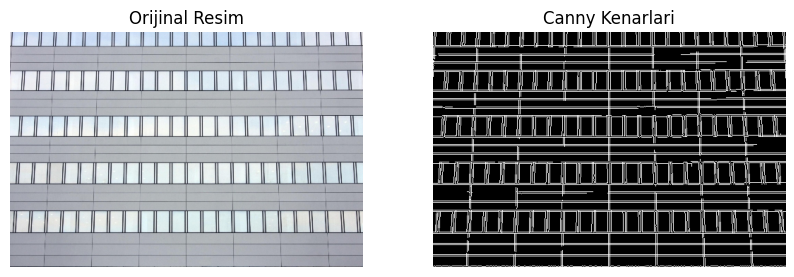

In [9]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Resmi oku
resim = cv2.imread("/content/resim3.jpeg")

if resim is None:
    raise FileNotFoundError("resim3.jpeg bulunamadi!")

# Resmi kucult
h, w = resim.shape[:2]

if max(h, w) > 500:
    oran = 500 / max(h, w)
    resim = cv2.resize(resim, None, fx=oran, fy=oran)

# Gri tona cevir
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)

# Canny ile kenarlari bul
kenarlar = cv2.Canny(gri, 50, 150)

# Kenar noktalarini CUDA icin kaydet
ys, xs = np.where(kenarlar > 0)

xs = xs.astype(np.int32)
ys = ys.astype(np.int32)

import struct

H, W = kenarlar.shape

with open("kenar_noktalari.bin", "wb") as f:
    f.write(struct.pack("iii", W, H, len(xs)))
    f.write(xs.tobytes())
    f.write(ys.tobytes())

print("Kenar noktasi sayisi:", len(xs))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Resim")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarlari")
plt.axis("off")

plt.show()


In [10]:

%%writefile hough_cuda.cu
#include <iostream>
#include <vector>
#include <cmath>
#include <cstdio>
#include <chrono>
#include <cuda_runtime.h>

using namespace std;

#define THETA 180
#define PI 3.14159265358979323846

// CUDA paralel Hough oylamasi
__global__ void houghKernel(
    const int* xs,
    const int* ys,
    int N,
    int* accumulator,
    const float* sinTable,
    const float* cosTable,
    int rhoMax,
    int rhoCount
) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;

    if (idx >= N * THETA)
        return;

    int nokta = idx / THETA;
    int theta = idx % THETA;

    int x = xs[nokta];
    int y = ys[nokta];

    int rho = (int)roundf(
        x * cosTable[theta] +
        y * sinTable[theta]
    );

    int ri = rho + rhoMax;

    if (ri >= 0 && ri < rhoCount) {
        atomicAdd(
            &accumulator[theta * rhoCount + ri],
            1
        );
    }
}

int main() {
    int W, H, N;

    FILE* f = fopen("kenar_noktalari.bin", "rb");

    if (!f) {
        cout << "Kenar dosyasi bulunamadi!" << endl;
        return 1;
    }

    fread(&W, sizeof(int), 1, f);
    fread(&H, sizeof(int), 1, f);
    fread(&N, sizeof(int), 1, f);

    vector<int> xs(N), ys(N);

    fread(xs.data(), sizeof(int), N, f);
    fread(ys.data(), sizeof(int), N, f);
    fclose(f);

    int rhoMax = (int)ceil(sqrt(
        (double)W * W + (double)H * H
    ));

    int rhoCount = 2 * rhoMax + 1;
    int accSize = THETA * rhoCount;

    // Sin ve cos degerlerini onceden hesapla
    vector<float> sinTable(THETA);
    vector<float> cosTable(THETA);

    for (int t = 0; t < THETA; t++) {
        float aci = t * PI / 180.0f;
        sinTable[t] = sinf(aci);
        cosTable[t] = cosf(aci);
    }

    // CPU Hough
    vector<int> cpuAcc(accSize, 0);

    auto cpuStart = chrono::high_resolution_clock::now();

    for (int i = 0; i < N; i++) {
        for (int t = 0; t < THETA; t++) {
            int rho = (int)roundf(
                xs[i] * cosTable[t] +
                ys[i] * sinTable[t]
            );

            int ri = rho + rhoMax;

            if (ri >= 0 && ri < rhoCount)
                cpuAcc[t * rhoCount + ri]++;
        }
    }

    auto cpuEnd = chrono::high_resolution_clock::now();

    double cpuMs = chrono::duration<double, milli>(
        cpuEnd - cpuStart
    ).count();

    // GPU bellekleri
    int *d_xs, *d_ys, *d_acc;
    float *d_sin, *d_cos;

    cudaMalloc(&d_xs, N * sizeof(int));
    cudaMalloc(&d_ys, N * sizeof(int));
    cudaMalloc(&d_acc, accSize * sizeof(int));
    cudaMalloc(&d_sin, THETA * sizeof(float));
    cudaMalloc(&d_cos, THETA * sizeof(float));

    cudaMemcpy(d_xs, xs.data(), N * sizeof(int), cudaMemcpyHostToDevice);
    cudaMemcpy(d_ys, ys.data(), N * sizeof(int), cudaMemcpyHostToDevice);
    cudaMemcpy(d_sin, sinTable.data(), THETA * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_cos, cosTable.data(), THETA * sizeof(float), cudaMemcpyHostToDevice);

    cudaMemset(d_acc, 0, accSize * sizeof(int));

    int threads = 256;
    int blocks = (N * THETA + threads - 1) / threads;

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);

    houghKernel<<<blocks, threads>>>(
        d_xs, d_ys, N, d_acc,
        d_sin, d_cos, rhoMax, rhoCount
    );

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    cudaError_t err = cudaGetLastError();
    if (err != cudaSuccess) {
        cout << "CUDA hatasi: "
             << cudaGetErrorString(err) << endl;
        return 1;
    }

    float gpuMs = 0;
    cudaEventElapsedTime(&gpuMs, start, stop);

    vector<int> gpuAcc(accSize);

    cudaMemcpy(
        gpuAcc.data(), d_acc,
        accSize * sizeof(int),
        cudaMemcpyDeviceToHost
    );

    int fark = 0;

    for (int i = 0; i < accSize; i++) {
        if (cpuAcc[i] != gpuAcc[i])
            fark++;
    }

    cout << "CPU suresi: " << cpuMs << " ms" << endl;
    cout << "GPU kernel suresi: " << gpuMs << " ms" << endl;
    cout << "Farkli oylama hucresi: " << fark << endl;

    if (gpuMs > 0)
        cout << "Kernel hizlanmasi: "
             << cpuMs / gpuMs << " kat" << endl;

    // GPU sonucunu kaydet
    FILE* out = fopen("hough_sonuc.bin", "wb");

    fwrite(&rhoMax, sizeof(int), 1, out);
    fwrite(&rhoCount, sizeof(int), 1, out);
    fwrite(gpuAcc.data(), sizeof(int), accSize, out);

    fclose(out);

    cudaFree(d_xs);
    cudaFree(d_ys);
    cudaFree(d_acc);
    cudaFree(d_sin);
    cudaFree(d_cos);

    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    return 0;
}


Writing hough_cuda.cu


In [11]:
!nvcc -O2 hough_cuda.cu -o hough_cuda
!./hough_cuda

hough_cuda.cu(60): warning #1650-D: result of call is not used
      fread(&W, sizeof(int), 1, f);
      ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

hough_cuda.cu(61): warning #1650-D: result of call is not used
      fread(&H, sizeof(int), 1, f);
      ^

hough_cuda.cu(62): warning #1650-D: result of call is not used
      fread(&N, sizeof(int), 1, f);
      ^

hough_cuda.cu(66): warning #1650-D: result of call is not used
      fread(xs.data(), sizeof(int), N, f);
      ^

hough_cuda.cu(67): warning #1650-D: result of call is not used
      fread(ys.data(), sizeof(int), N, f);
      ^

hough_cuda.cu(60): warning #1650-D: result of call is not used
      fread(&W, sizeof(int), 1, f);
      ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

hough_cuda.cu(61): warning #1650-D: result of call is not used
      fread(&H, sizeof(int), 1, f);
      ^

hough_cuda.cu(62): warning #1650-D: result of call is not used
      fre

Bulunan dogru sayisi: 15


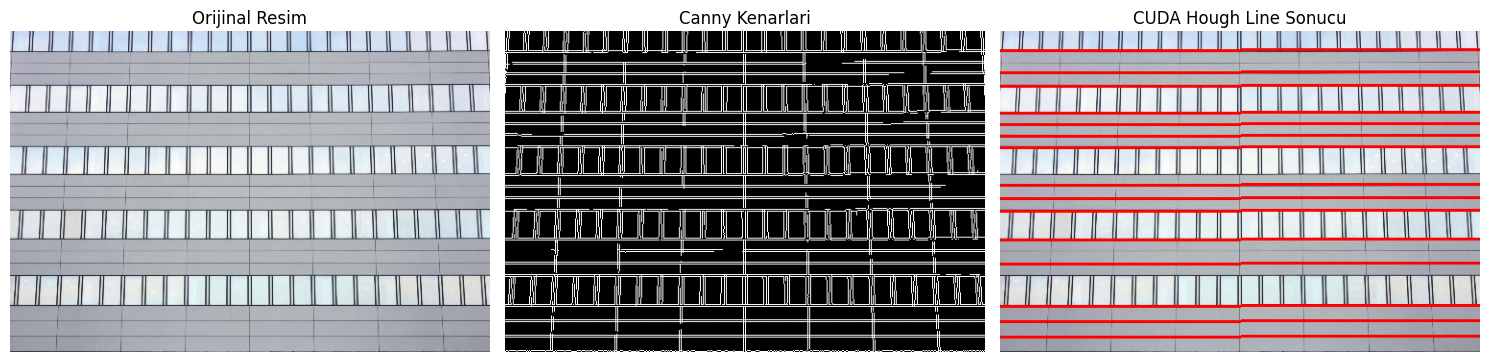

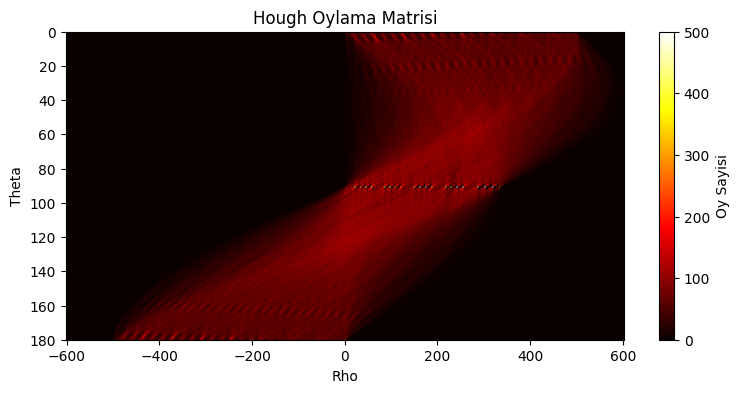

In [12]:

import struct

# CUDA oylama sonucunu oku
with open("hough_sonuc.bin", "rb") as f:
    rhoMax, rhoCount = struct.unpack("ii", f.read(8))
    acc = np.frombuffer(f.read(), dtype=np.int32).copy()

acc = acc.reshape(180, rhoCount)

# Esik degeri
esik = max(30, int(acc.max() * 0.45))

# Yuksek oy alan dogrulari bul
adaylar = []

for t in range(180):
    for ri in range(rhoCount):
        oy = acc[t, ri]

        if oy < esik:
            continue

        t0 = max(0, t - 2)
        t1 = min(180, t + 3)
        r0 = max(0, ri - 8)
        r1 = min(rhoCount, ri + 9)

        if oy == np.max(acc[t0:t1, r0:r1]):
            adaylar.append((int(oy), t, ri - rhoMax))

adaylar.sort(reverse=True)

# Benzer dogrulari ele
secilen = []

for oy, t, rho in adaylar:
    tekrar = False

    for _, t2, rho2 in secilen:
        aci_farki = abs(t - t2)
        aci_farki = min(aci_farki, 180 - aci_farki)

        if aci_farki < 5 and abs(rho - rho2) < 12:
            tekrar = True
            break

    if not tekrar:
        secilen.append((oy, t, rho))

    if len(secilen) >= 15:
        break

# Dogrulari orijinal resme ciz
sonuc = resim.copy()

for oy, t, rho in secilen:
    theta = np.deg2rad(t)

    a = np.cos(theta)
    b = np.sin(theta)

    x0 = a * rho
    y0 = b * rho

    x1 = int(x0 - 1000 * b)
    y1 = int(y0 + 1000 * a)

    x2 = int(x0 + 1000 * b)
    y2 = int(y0 - 1000 * a)

    cv2.line(
        sonuc,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

print("Bulunan dogru sayisi:", len(secilen))

# Sonuclari goster
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Resim")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarlari")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("CUDA Hough Line Sonucu")
plt.axis("off")

plt.tight_layout()
plt.show()

# Hough oylama matrisi
plt.figure(figsize=(9, 4))
plt.imshow(
    acc,
    cmap="hot",
    aspect="auto",
    extent=[-rhoMax, rhoMax, 180, 0]
)
plt.colorbar(label="Oy Sayisi")
plt.title("Hough Oylama Matrisi")
plt.xlabel("Rho")
plt.ylabel("Theta")
plt.show()
